# Road Damage / Pothole Detection — RDD2022 (India subset)
ANN & Deep Learning Major Project

**Before running:** Runtime → Change runtime type → **T4 GPU** → Save.

Run the cells top to bottom. In later sessions, skip Steps 4–6 and use **Step 7 (Restore)** instead.

## Step 1 — Check the GPU

In [ ]:
!nvidia-smi

Wed Oct  7 07:21:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 2 — Mount Google Drive and create the project folder

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/RDD_Project'
!mkdir -p {PROJECT}/runs
print('Project folder:', PROJECT)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/RDD_Project


## Step 3 — Install libraries

In [ ]:
!pip install -q ultralytics huggingface_hub
import ultralytics
ultralytics.checks()

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)


## Step 4 — Download the India subset of RDD2022 from Hugging Face
Source: `dronefreak/RDD2022` (YOLO-format redistribution of RDD2022, 4 CRDDC classes).
Downloads to Colab's local disk (fast). Takes a few minutes.

In [ ]:
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="dronefreak/RDD2022",
    repo_type="dataset",
    local_dir="/content/RDD2022",
    allow_patterns=[
        "data/data.yaml",
        "data/images/*/*/India_*",
        "data/labels/*/*/India_*",
    ],
)
print("Download finished")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15413 files:   0%|          | 0/15413 [00:00<?, ?it/s]

HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/RDD2022/resolve/72b01f94c2e5bfe430861afd73995f2d412b8855/data/labels/train/shard_002/India_003253.txt
Rate limited. Waiting 119.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/RDD2022/resolve/72b01f94c2e5bfe430861afd73995f2d412b8855/data/labels/train/shard_002/India_003254.txt
Rate limited. Waiting 119.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/RDD2022/resolve/72b01f94c2e5bfe430861afd73995f2d412b8855/data/labels/train/shard_002/India_003259.txt
Rate limited. Waiting 119.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/dronefreak/RDD2022/resolve/72b01f94c2e5bfe430861afd73995f2d412b8855/data/labels/train/shard_002/India_003260.txt
Rate limited. Waiting 119.0s before retry [Retry 1/5].
HTTP Error 429 thrown wh

Download finished


## Step 5 — Check what was downloaded

In [ ]:
import glob, os

DATA = '/content/RDD2022/data'
for split in ['train', 'valid', 'test']:
    imgs = glob.glob(f'{DATA}/images/{split}/**/*.jpg', recursive=True)
    lbls = glob.glob(f'{DATA}/labels/{split}/**/*.txt', recursive=True)
    print(f'{split:6s}: {len(imgs):5d} images | {len(lbls):5d} label files')

print()
!cat {DATA}/data.yaml

train :  5368 images |  5368 label files
valid :  1172 images |  1172 label files
test  :  1166 images |  1166 label files

path: .
train: images/train
val: images/valid
test: images/test
nc: 4
names:
  0: longitudinal_crack
  1: transverse_crack
  2: alligator_crack
  3: pothole


## Step 6 — Back up the dataset to Drive (one time only)
Zipping first is much faster than copying thousands of small files to Drive.

In [ ]:
%cd /content
!zip -qr {PROJECT}/rdd2022_india.zip RDD2022
!ls -lh {PROJECT}/rdd2022_india.zip

/content
-rw------- 1 root root 416M Oct  7 04:26 /content/drive/MyDrive/RDD_Project/rdd2022_india.zip


## Step 7 — Restore (USE THIS IN LATER SESSIONS instead of Steps 4–6)
Skip this cell in your first session.

In [ ]:
%cd /content
!unzip -q -o {PROJECT}/rdd2022_india.zip -d /content
DATA = '/content/RDD2022/data'
print('Restored to', DATA)

/content
Restored to /content/RDD2022/data


## Step 8 — Create the dataset config
Writes a `rdd_india.yaml` with absolute paths and the class names from the original `data.yaml`.

In [ ]:
import yaml

with open(f'{DATA}/data.yaml') as f:
    original = yaml.safe_load(f)

names = original['names']
if isinstance(names, list):
    names = {i: n for i, n in enumerate(names)}

config = {
    'path': DATA,
    'train': 'images/train',
    'val': 'images/valid',
    'test': 'images/test',
    'names': names,
}
with open('/content/rdd_india.yaml', 'w') as f:
    yaml.safe_dump(config, f, sort_keys=False)

!cat /content/rdd_india.yaml

path: /content/RDD2022/data
train: images/train
val: images/valid
test: images/test
names:
  0: longitudinal_crack
  1: transverse_crack
  2: alligator_crack
  3: pothole


## Step 9 — Look at a few labelled samples (good figure for the report)

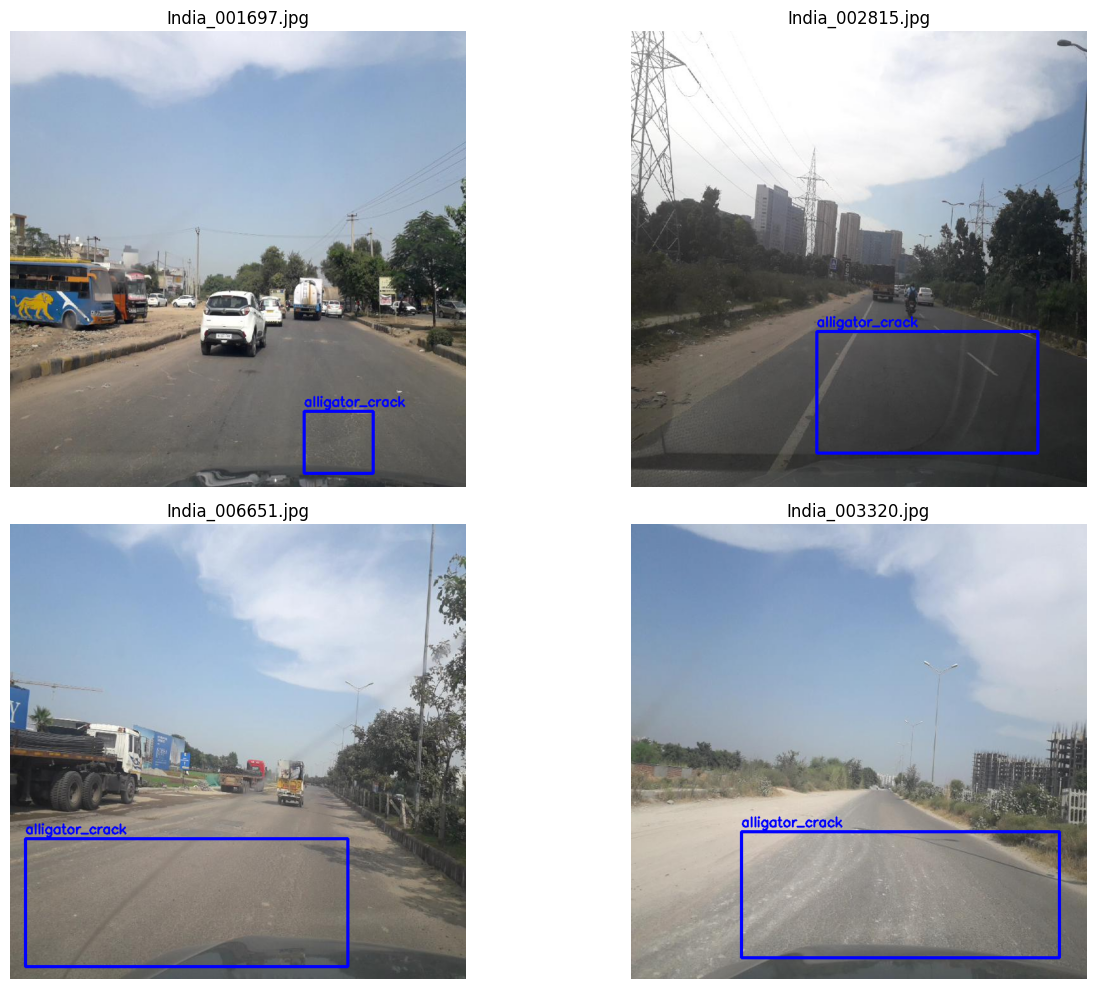

In [ ]:
import random, cv2
import matplotlib.pyplot as plt

colors = [(255,0,0), (0,200,0), (0,0,255), (255,165,0)]
imgs = glob.glob(f'{DATA}/images/train/**/*.jpg', recursive=True)
random.seed(0)
samples = []
for p in random.sample(imgs, 60):
    lp = p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    if os.path.exists(lp) and os.path.getsize(lp) > 0:
        samples.append((p, lp))
    if len(samples) == 4:
        break

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (p, lp) in zip(axes.flat, samples):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in open(lp):
        c, xc, yc, bw, bh = map(float, line.split())
        x1, y1 = int((xc - bw/2) * w), int((yc - bh/2) * h)
        x2, y2 = int((xc + bw/2) * w), int((yc + bh/2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), colors[int(c)], 3)
        cv2.putText(img, names[int(c)], (x1, max(y1 - 8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, colors[int(c)], 2)
    ax.imshow(img); ax.set_title(os.path.basename(p)); ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT}/sample_annotations.png', dpi=150)
plt.show()

In [ ]:
from collections import Counter

for split in ['train', 'valid', 'test']:
    counts = Counter()
    for lp in glob.glob(f'{DATA}/labels/{split}/**/*.txt', recursive=True):
        for line in open(lp):
            if line.strip():
                counts[int(line.split()[0])] += 1
    print(split, {names[c]: counts[c] for c in sorted(names)})

train {'longitudinal_crack': 1103, 'transverse_crack': 50, 'alligator_crack': 1428, 'pothole': 969}
valid {'longitudinal_crack': 223, 'transverse_crack': 11, 'alligator_crack': 307, 'pothole': 202}
test {'longitudinal_crack': 229, 'transverse_crack': 7, 'alligator_crack': 286, 'pothole': 201}


## Step 10 — Train the baseline: YOLOv8s
Results and checkpoints are saved straight to Drive, so nothing is lost if Colab disconnects.
`patience=15` stops early if validation mAP stops improving.

In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')   # pretrained on COCO
model.train(
    data='/content/rdd_india.yaml',
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project=f'{PROJECT}/runs',
    name='yolov8s_india',
    exist_ok=True,
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rdd_india.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_india, nbs=64, nms=None, opset=None, optimize=False, optimi

## Step 11 — Resume training (only if Colab disconnected)
Run Steps 1, 2, 3, 7 and 8 first, then this cell.

In [ ]:
from ultralytics import YOLO

model = YOLO(f'{PROJECT}/runs/yolov8s_india/weights/last.pt')
model.train(resume=True)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rdd_india.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.00125, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/RDD_Project/runs/yolov8s_india/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f47d23d23c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

## Step 12 — Evaluate on the test split

In [ ]:
from ultralytics import YOLO

best = YOLO(f'{PROJECT}/runs/yolov8s_india/weights/best.pt')
metrics = best.val(
    data='/content/rdd_india.yaml',
    split='test',
    project=f'{PROJECT}/runs',
    name='yolov8s_india_test',
    exist_ok=True,
)
print(f'mAP@0.5      : {metrics.box.map50:.4f}')
print(f'mAP@0.5:0.95 : {metrics.box.map:.4f}')
print()
for i, name in names.items():
    print(f'{name:20s} AP@0.5 = {metrics.box.ap50[i]:.4f}')

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2211.1±871.3 MB/s, size: 66.2 KB)
val: Scanning /content/RDD2022/data/labels/test/shard_000... 1166 images, 725 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1166/1166 1.8Kit/s 0.6s
val: New cache created: /content/RDD2022/data/labels/test/shard_000.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 3.9it/s 18.7s
                   all       1166        723      0.369      0.332      0.316      0.139
    longitudinal_crack        162        229      0.454       0.31      0.267     0.0998
      transverse_crack          6          7          0          0    0.00146    0.00027
       alligator_crack        251        286      0.595      0.626      0.636      0.286
               pothole        149        201    

In [ ]:
import glob, os, random
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT = '/content/drive/MyDrive/RDD_Project'
DATA = '/content/RDD2022/data'

if not os.path.exists(DATA):
    !unzip -q -o {PROJECT}/rdd2022_india.zip -d /content

best = YOLO(f'{PROJECT}/runs/yolov8s_india/weights/best.pt')
print('Test images:', len(glob.glob(f'{DATA}/images/test/**/*.jpg', recursive=True)))

Test images: 1166


## Step 13 — Run predictions on some test images


0: 640x640 (no detections), 23.5ms
1: 640x640 3 longitudinal_cracks, 23.5ms
2: 640x640 (no detections), 23.5ms
3: 640x640 (no detections), 23.5ms
Speed: 2.1ms preprocess, 23.5ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)


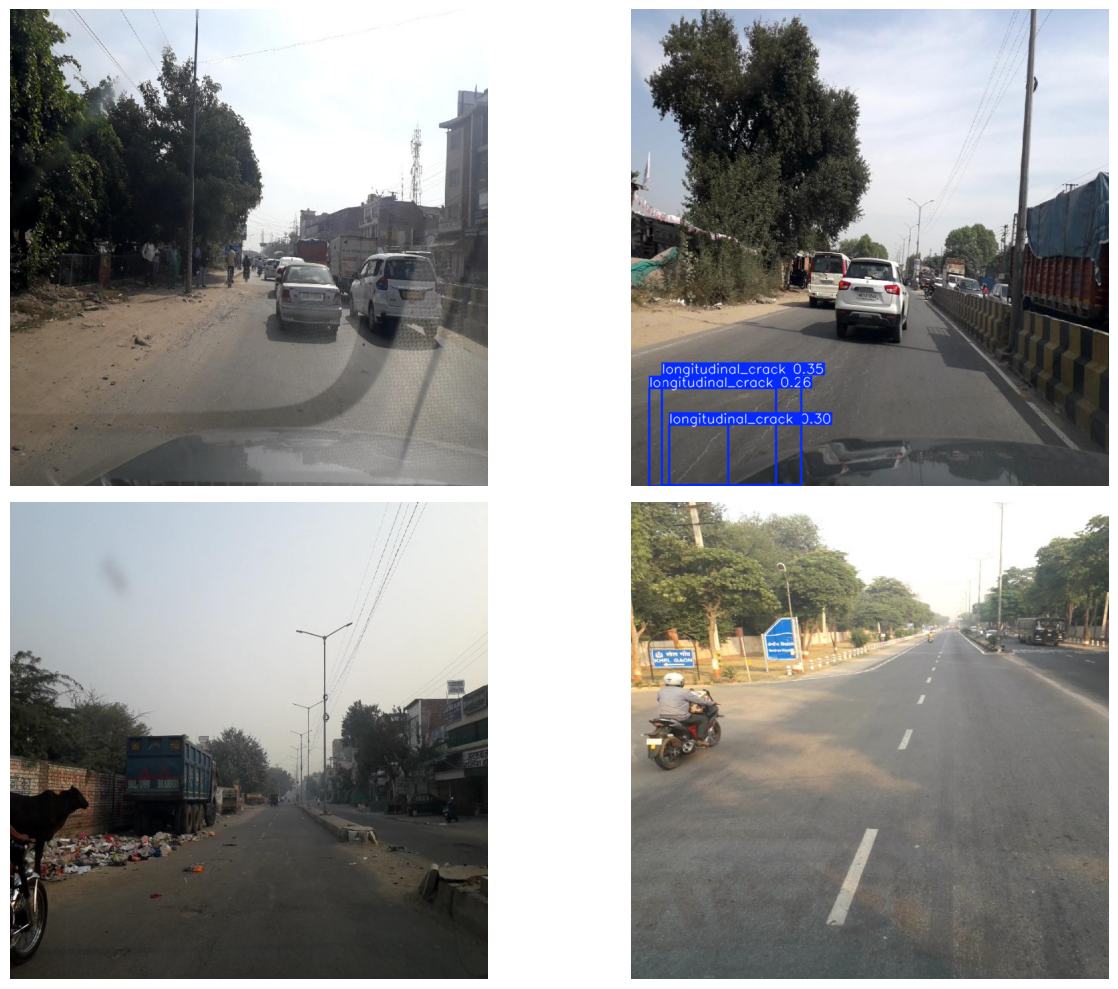

In [ ]:
test_imgs = glob.glob(f'{DATA}/images/test/**/*.jpg', recursive=True)
random.seed(1)
picks = random.sample(test_imgs, 4)

results = best.predict(picks, conf=0.25)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, r in zip(axes.flat, results):
    ax.imshow(r.plot()[:, :, ::-1]); ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT}/sample_predictions.png', dpi=150)
plt.show()